# Play Tic-Tac-Toe Interactively (Simple Implementation)

To play interactively, you need to run the whole notebook in JupyterLab and scroll down.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

## Implement an Interactive Game


### Interactive Player

Implement the interactive player. It shows the board and asks you for the move.

In [3]:
from IPython.display import clear_output

def interactive_player(board, player = None):
    clear_output(wait = False)
    show_board(board, help = True)
    
    available = actions(board)
    print(f'Available actions are: {available}')

    retry = True
    while retry:
        try:
            move = int(input("Your move (0-8 or -1 to end the game):\n"))            
        
            if move in available:
                retry = False
            else:
                raise ValueError()
        except ValueError:
            if move == -1:
                print("Game ended by user.")
                raise Exception("Game ended by user.")
            
            print("Please enter a valid move.")
            

    return(move)

## Start an interactive game as x

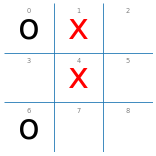

Available actions are: [2, 3, 5, 7, 8]


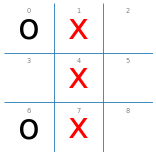

{'x': 1, 'o': 0, 'd': 0}

In [4]:
play(interactive_player, random_player, N = 1,  show_final_board=True)

### Start an interactive game as o

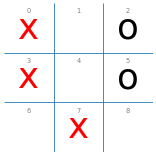

Available actions are: [1, 4, 6, 8]


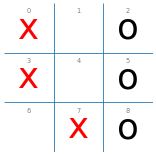

{'x': 0, 'o': 1, 'd': 0}

In [5]:
play(random_player, interactive_player, N = 1, show_final_board = True)

## Sử dụng các Agent ở các bài trước, nhập vai chơi với Agents 
- Alpha-Beta
- Heuristic Alpha-Beta cắt ở độ sâu 2
- Pure Monte Carlo 100 playout
- Monte Carlo + UCB1 100 playout

## 1. Alpha-Beta

In [ ]:
import math
import numpy as np

def eval_fun(state, player):
    u = utility(state, player)
    if u is not None:
        return u, True

    b = np.array(state).reshape((3, 3))
    lines = list(b) + list(b.T) + [b.diagonal(), np.fliplr(b).diagonal()]
    score = 0
    for line in lines:
        if sum(line == player) == 2 and ' ' in line:        score += 0.4
        if sum(line == other(player)) == 2 and ' ' in line: score -= 0.4
    return score, False


def max_value(state, player, alpha, beta, depth, cutoff):
    v, done = eval_fun(state, player)
    if done or (cutoff is not None and depth >= cutoff):
        return v, None
    best_v, best_move = -math.inf, None
    for a in actions(state):
        v, _ = min_value(result(state, player, a), player, alpha, beta, depth + 1, cutoff)
        if v > best_v:
            best_v, best_move = v, a
            alpha = max(alpha, v)
        if best_v >= beta:
            break
    return best_v, best_move


def min_value(state, player, alpha, beta, depth, cutoff):
    v, done = eval_fun(state, player)
    if done or (cutoff is not None and depth >= cutoff):
        return v, None
    best_v, best_move = math.inf, None
    for a in actions(state):
        v, _ = max_value(result(state, other(player), a), player, alpha, beta, depth + 1, cutoff)
        if v < best_v:
            best_v, best_move = v, a
            beta = min(beta, v)
        if best_v <= alpha:
            break
    return best_v, best_move


In [12]:
def alpha_beta_player(board, player = 'x'):
    value, move = max_value(board, player, -math.inf, math.inf, 0, cutoff = None)  # không cắt
    return move

### Human play "X"

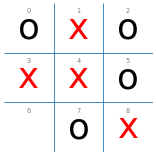

Available actions are: [6]


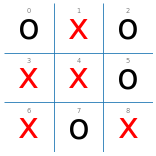

{'x': 0, 'o': 0, 'd': 1}

In [20]:
play(interactive_player, alpha_beta_player, N = 1, show_final_board = True)

### Human play "O"

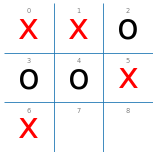

Available actions are: [7, 8]


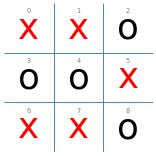

{'x': 0, 'o': 0, 'd': 1}

In [24]:
play(alpha_beta_player, interactive_player, N = 1, show_final_board = True)

## 2. Heristic Alpha - Beta cắt ở độc sâu = 2

In [13]:
def heuristic_player(board, player = 'x'):
    value, move = max_value(board, player, -math.inf, math.inf, 0, cutoff = 2)     # cắt ở độ sâu 2
    return move

### Human play "X"

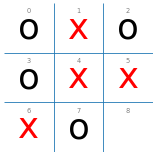

Available actions are: [8]


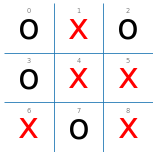

{'x': 0, 'o': 0, 'd': 1}

In [25]:
play(interactive_player, heuristic_player, N = 1, show_final_board = True)

### Human play "O"

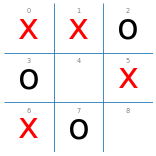

Available actions are: [4, 8]


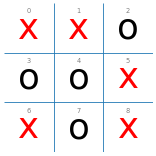

{'x': 0, 'o': 0, 'd': 1}

In [26]:
play(heuristic_player, interactive_player, N = 1, show_final_board = True)

In [28]:
def playout(board, action, player):
    """Đi nước `action`, sau đó hai bên đánh ngẫu nhiên đến hết ván. Trả về +1 / 0 / -1 cho player."""
    state = result(board, player, action)
    turn = other(player)
    while utility(state, player) is None:
        state = result(state, turn, np.random.choice(actions(state)))
        turn = other(turn)
    return utility(state, player)

## 3. Pure Monte Carlo

In [31]:
def pmcs_player(board, player = 'x', N = 100):
    acts = actions(board)
    n = max(1, N // len(acts))                                  # chia đều N lượt thử cho các nước
    scores = {a: np.mean([playout(board, a, player) for _ in range(n)]) for a in acts}
    return max(scores, key = scores.get)                        # nước có điểm trung bình cao nhất

### Human play "X"

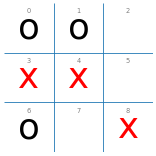

Available actions are: [2, 5, 7]


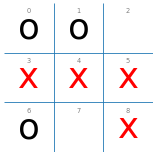

{'x': 1, 'o': 0, 'd': 0}

In [30]:
play(interactive_player, pmcs_player, N = 1, show_final_board = True)

### Human play "O"

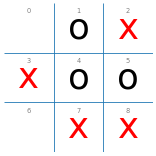

Available actions are: [0, 6]


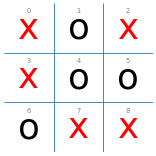

{'x': 0, 'o': 0, 'd': 1}

In [32]:
play(pmcs_player, interactive_player, N = 1, show_final_board = True)

## 4. Monte Carlo + UCB1

In [ ]:
def ucb1_player(board, player = 'x', N = 100):
    acts = actions(board)
    total = {a: 0 for a in acts}     # tổng điểm của mỗi nước
    count = {a: 0 for a in acts}     # số lần đã thử mỗi nước

    for i in range(1, N + 1):
        untried = [a for a in acts if count[a] == 0]
        if untried:
            a = untried[0]                                      # nước chưa thử thì thử trước
        else:                                                   # chọn nước có UCB1 lớn nhất
            a = max(acts, key = lambda a: total[a] / count[a] + math.sqrt(2 * math.log(i) / count[a]))
        total[a] += playout(board, a, player)
        count[a] += 1

    return max(acts, key = lambda a: count[a])                  # nước được thử nhiều nhất

### Human play "X"

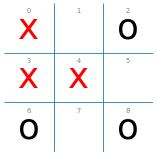

Available actions are: [1, 5, 7]


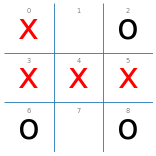

{'x': 1, 'o': 0, 'd': 0}

In [33]:
play(interactive_player, ucb1_player, N = 1, show_final_board = True)

### Human play "O"

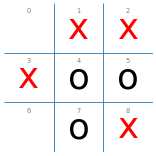

Available actions are: [0, 6]


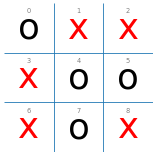

{'x': 0, 'o': 0, 'd': 1}

In [35]:
play(ucb1_player, interactive_player, N = 1, show_final_board = True)

## Tổng kết lại các bàn thắng của Human vs Agents

| Tác tử | Người chơi cầm X (đi trước) | Người chơi cầm O (tác tử đi trước) |
|---|---|---|
| Random (ván mẫu ban đầu) | Người thắng | Người thắng |
| 1. Alpha-Beta | Hòa | Hòa |
| 2. Heuristic Alpha-Beta (độ sâu 2) | Hòa | Hòa |
| 3. Pure Monte Carlo (100 playout) | **Người thắng** (hàng 3-4-5) | Hòa |
| 4. Monte Carlo + UCB1 (100 playout) | **Người thắng** (hàng 3-4-5) | Hòa |


## Nhận xét chiến lược của các tác tử

**1. Alpha-Beta (tìm kiếm đầy đủ)**
* Không thua ván nào, cả hai ván đều hòa. Tác tử xét hết mọi nước đi đến cuối ván và giả định đối thủ luôn chơi tốt nhất (minimax), nên nó chặn mọi đường chờ thắng và không để người chơi tạo được thế hai đường cùng lúc. Với Tic-Tac-Toe, khi cả hai bên chơi đúng thì kết quả là hòa, nên hòa là kết quả tốt nhất người chơi có thể đạt được.
* Khi cầm X, tác tử luôn mở đầu ở ô góc 0. Lý do: trên bàn trống, mọi nước đầu tiên đều có giá trị 0 (dẫn đến hòa nếu chơi đúng), và thuật toán chọn nước đầu tiên trong danh sách đạt giá trị tốt nhất.
* Nước đi hoàn toàn tất định: cùng một thế cờ luôn cho cùng một nước đi.
* Điểm yếu: phải duyệt cả cây trò chơi. Với bàn 3×3 thì vẫn nhanh, nhưng trên bàn lớn hơn như Connect 4 (6×7) thì không khả thi.

**2. Heuristic Alpha-Beta (cắt ở độ sâu 2)**
* Cả hai ván đều hòa. Trong hai ván này, tác tử chơi chắc chắn như Alpha-Beta đầy đủ.
* Khi cầm X, tác tử cũng mở đầu ở ô góc 0.
* Nhìn trước 2 nước (nước của mình và nước đáp trả của đối thủ) là đủ để thấy cơ hội thắng ngay và chặn ngay khi đối thủ có 2 quân thẳng hàng. Ngoài độ sâu đó, tác tử dựa vào `eval_fun` (đếm số đường có 2 quân và 1 ô trống) để đoán thế cờ.
* Điểm yếu về lý thuyết: những cái bẫy cần nhìn sâu hơn 2 nước mới thấy (ví dụ thế cờ sẽ dẫn đến hai đường chờ thắng ở lượt sau) có thể bị bỏ sót. Đổi lại, tác tử duyệt ít nút hơn nhiều so với Alpha-Beta đầy đủ, nên nhanh hơn và dùng được trên bàn lớn.

**3. Pure Monte Carlo (100 playout)**
* Thua khi người chơi cầm X và hòa khi người chơi cầm O. Trong ván thua, X có 2 quân ở ô 3 và 4 nhưng tác tử không chặn được ô 5, nên X hoàn thành hàng 3-4-5.
* Tác tử đánh giá mỗi nước bằng cách cho hai bên đánh **ngẫu nhiên** đến hết ván. Như vậy nó ngầm giả định đối thủ chơi ngẫu nhiên, nên đánh giá thấp nguy cơ khi gặp người chơi đi đúng. Ngoài ra, 100 playout chia đều cho khoảng 6–8 nước nên mỗi nước chỉ được thử khoảng 12–16 lần, và ước lượng còn nhiều nhiễu.
* Nước đi có yếu tố ngẫu nhiên: cùng một thế cờ có thể cho nước đi khác nhau ở mỗi lần chạy, và nước mở đầu khi cầm X cũng không cố định.

**4. Monte Carlo + UCB1 (100 playout)**
* Kết quả giống Pure Monte Carlo: thua khi người chơi cầm X và hòa khi người chơi cầm O. Trong ván thua, X có 3 quân ở ô 0, 3, 4, nằm trên nhiều đường chờ thắng cùng lúc (hàng 3-4-5, cột 0-3-6, chéo 0-4-8). Tác tử chặn được ô 6 và 8 nhưng không chặn được ô 5.
* UCB1 dồn nhiều lượt thử hơn cho các nước có vẻ tốt thay vì chia đều, nên với cùng 100 playout nó ước lượng tốt hơn Pure Monte Carlo. Tuy nhiên, nó vẫn dựa trên playout ngẫu nhiên nên không nhận ra được thế "hai đường chờ thắng" mà người chơi tạo ra.

**Nhìn chung**
* **Tác tử tìm kiếm cây theo minimax (Alpha-Beta, Heuristic Alpha-Beta) chơi chắc chắn hơn tác tử Monte Carlo.** Hai tác tử này suy luận rằng đối thủ sẽ chọn nước tốt nhất, nên không bị bẫy trong các ván đã chơi. Hai tác tử Monte Carlo giả định đối thủ đánh ngẫu nhiên nên bị người chơi khai thác.
* **Người đi trước có lợi thế:** trong 8 ván với 4 tác tử, cả hai ván người chơi thắng đều là khi người chơi cầm X. Khi người chơi cầm O (tác tử đi trước), cả 4 ván với 4 tác tử đều hòa.
* **Đánh đổi giữa sức mạnh và thời gian:** Alpha-Beta đầy đủ mạnh nhất nhưng tốn nhiều phép tính nhất. Tác tử Monte Carlo có thể mạnh hơn nếu tăng số playout (ví dụ 1000), nhưng sẽ chậm hơn.